Day 5: Train a CNN on CIFAR-10

**Goal:** Train a CNN from scratch, log training/validation curves, and save the metrics. The required one-page explainer is a separate file named `anatomy-of-training-loop.md`.

1. Setup
CIFAR-10 has 32×32 RGB images in 10 classes. I will use a validation split from the training set, then evaluate on the official test set after training.

In [1]:
import random, csv
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

OUTPUT_DIR = Path("day5_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

Device: cpu


2. Load and normalize CIFAR-10
`ToTensor()` scales pixels to 0–1. Normalization subtracts each channel's mean and divides by its standard deviation, giving the channels a more consistent scale. Use the same normalization for all splits.

In [2]:
MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

full_train = datasets.CIFAR10(root="data", train=True, download=True, transform=transform)
test_data = datasets.CIFAR10(root="data", train=False, download=True, transform=transform)
train_data, val_data = random_split(
    full_train, [45000, 5000], generator=torch.Generator().manual_seed(SEED)
)
BATCH_SIZE = 128
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())
class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
print("Train:", len(train_data), "| Validation:", len(val_data), "| Test:", len(test_data))

100%|██████████| 170M/170M [41:53<00:00, 67.8kB/s]


Train: 45000 | Validation: 5000 | Test: 10000


Image batch shape: torch.Size([128, 3, 32, 32])


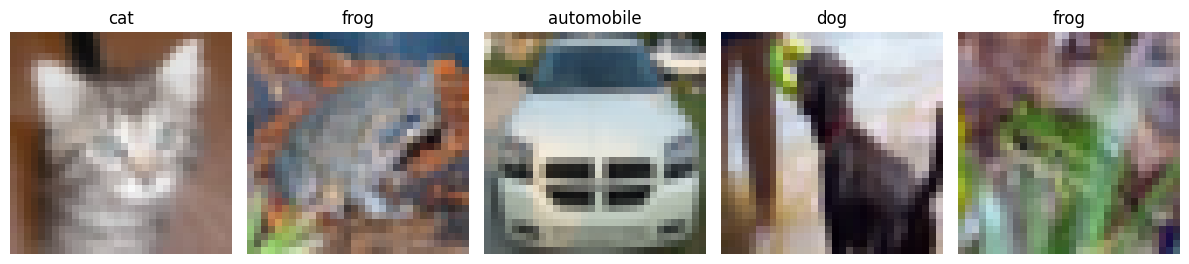

In [3]:
# Inspect a batch and display images (reverse normalization for display only)
images, labels = next(iter(train_loader))
print("Image batch shape:", images.shape)
mean = torch.tensor(MEAN).view(3, 1, 1)
std = torch.tensor(STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for i, ax in enumerate(axes):
    image = (images[i] * std + mean).clamp(0, 1)
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(class_names[labels[i].item()])
    ax.axis("off")
plt.tight_layout(); plt.show()

3. Define the CNN
The model learns features with convolution layers, uses ReLU activations and max pooling, then classifies the image. The final layer returns 10 logits. `CrossEntropyLoss` expects logits, so there is no softmax in the model.

In [4]:
class CIFAR10CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(128 * 4 * 4, 128), nn.ReLU(), nn.Linear(128, 10)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model = CIFAR10CNN().to(device)
print(model)
with torch.no_grad():
    print("Output shape for 4 images:", model(images[:4].to(device)).shape)

CIFAR10CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Output shape for 4 images: torch.Size([4, 10])


4. Loss, optimizer, and training functions
I use cross-entropy loss for the 10-class task and Adam to update the model parameters. The loop records average loss and accuracy for each epoch.

In [5]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

def run_epoch(loader, training):
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            logits = model(x)
            loss = loss_fn(logits, y)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            n = y.size(0)
            total_loss += loss.item() * n
            correct += (logits.argmax(1) == y).sum().item()
            total += n
    return total_loss / total, correct / total

5. Train and log curves
This trains for 10 epochs. Training and validation metrics are saved in `history`; plots and a CSV log are saved in `day5_outputs`. Training time depends on the runtime selected in Colab.

In [6]:
EPOCHS = 10
history = {"epoch": [], "train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = run_epoch(train_loader, training=True)
    val_loss, val_acc = run_epoch(val_loader, training=False)
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss); history["train_accuracy"].append(train_acc)
    history["val_loss"].append(val_loss); history["val_accuracy"].append(val_acc)
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {train_loss:.4f}, acc {train_acc:.2%} | val loss {val_loss:.4f}, acc {val_acc:.2%}")

Epoch 01/10 | train loss 1.4921, acc 45.88% | val loss 1.1901, acc 57.38%
Epoch 02/10 | train loss 1.0586, acc 62.45% | val loss 0.9893, acc 64.38%
Epoch 03/10 | train loss 0.8717, acc 69.64% | val loss 0.8586, acc 69.08%
Epoch 04/10 | train loss 0.7540, acc 73.52% | val loss 0.8076, acc 71.78%
Epoch 05/10 | train loss 0.6495, acc 77.34% | val loss 0.7554, acc 73.54%
Epoch 06/10 | train loss 0.5707, acc 80.12% | val loss 0.7404, acc 73.96%
Epoch 07/10 | train loss 0.4948, acc 82.81% | val loss 0.7474, acc 74.28%
Epoch 08/10 | train loss 0.4213, acc 85.26% | val loss 0.7687, acc 74.94%
Epoch 09/10 | train loss 0.3594, acc 87.37% | val loss 0.7999, acc 74.76%
Epoch 10/10 | train loss 0.2941, acc 89.70% | val loss 0.8398, acc 74.84%


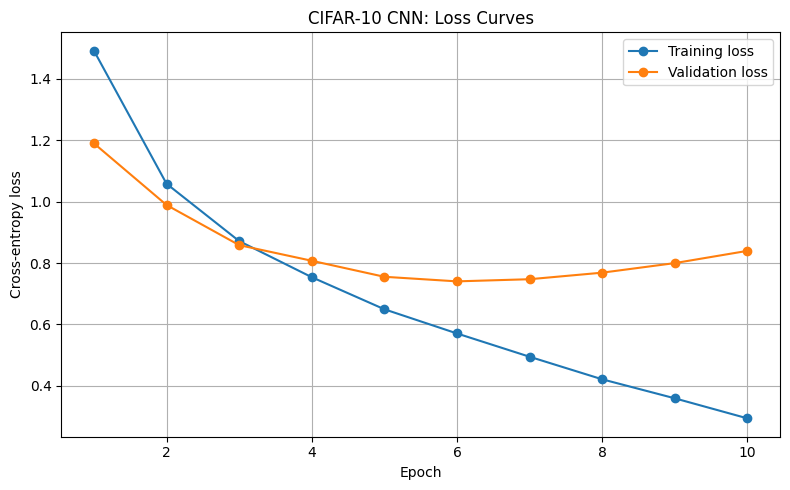

Saved: day5_outputs/loss_curves.png


In [7]:
epochs = history["epoch"]
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], marker="o", label="Training loss")
plt.plot(epochs, history["val_loss"], marker="o", label="Validation loss")
plt.xlabel("Epoch"); plt.ylabel("Cross-entropy loss"); plt.title("CIFAR-10 CNN: Loss Curves")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(OUTPUT_DIR / "loss_curves.png", dpi=150)
plt.show()
print("Saved:", OUTPUT_DIR / "loss_curves.png")

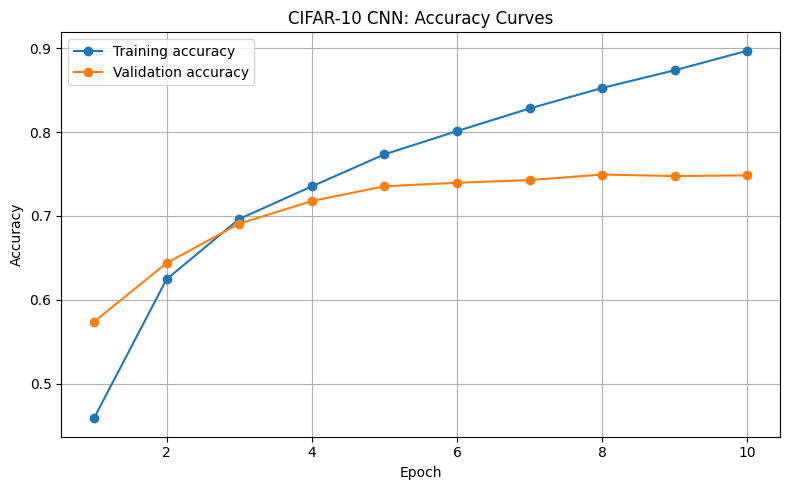

Saved: day5_outputs/accuracy_curves.png


In [8]:
plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_accuracy"], marker="o", label="Training accuracy")
plt.plot(epochs, history["val_accuracy"], marker="o", label="Validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("CIFAR-10 CNN: Accuracy Curves")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(OUTPUT_DIR / "accuracy_curves.png", dpi=150)
plt.show()
print("Saved:", OUTPUT_DIR / "accuracy_curves.png")

In [9]:
metrics_path = OUTPUT_DIR / "training_metrics.csv"
with open(metrics_path, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=history.keys())
    writer.writeheader()
    for i in range(len(history["epoch"])):
        writer.writerow({key: history[key][i] for key in history})
print("Saved:", metrics_path)

Saved: day5_outputs/training_metrics.csv


6. Final test evaluation
The official test set is used only after training to estimate generalization. It is not used to update weights.

In [10]:
test_loss, test_accuracy = run_epoch(test_loader, training=False)
print(f"Final test loss: {test_loss:.4f}")
print(f"Final test accuracy: {test_accuracy:.2%}")

Final test loss: 0.8807
Final test accuracy: 74.39%


7. Save model weights

In [11]:
model_path = OUTPUT_DIR / "cifar10_cnn_state_dict.pth"
torch.save(model.state_dict(), model_path)
print("Saved model weights:", model_path)
print("Output files:", sorted(p.name for p in OUTPUT_DIR.iterdir()))

Saved model weights: day5_outputs/cifar10_cnn_state_dict.pth
Output files: ['accuracy_curves.png', 'cifar10_cnn_state_dict.pth', 'loss_curves.png', 'training_metrics.csv']


8. Required deliverable checklist

- [ ] Train a CNN from scratch on CIFAR-10 (no pretrained model).
- [ ] Log training/validation loss and accuracy.
- [ ] Save `day5_outputs/loss_curves.png`.
- [ ] Save `day5_outputs/accuracy_curves.png`.
- [ ] Save `day5_outputs/training_metrics.csv`.
- [ ] Add `anatomy-of-training-loop.md` to the same GitHub `module 1` folder.


In [12]:
# Package the logged curves, metrics, and weights into one ZIP for GitHub
import shutil
zip_path = shutil.make_archive("day5_outputs", "zip", OUTPUT_DIR)
print("Created:", zip_path)

Created: /content/day5_outputs.zip
